# Лабораторная работа 7. Динамика обучения трансформера (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 3:** предобучение, оптимизация, масштабирование

**Цель.** Понять, от чего зависят устойчивость и скорость обучения трансформера: выбор оптимизатора, learning rate, расписание, параметризация.

**Что нужно сдать:**
1. Собственную реализацию AdamW, совпадающую с `torch.optim.AdamW`.
2. LR-sweep для SGD+momentum, Adam и AdamW с границей устойчивости.
3. Сравнение расписаний: constant, warmup + cosine, WSD.
4. Диагностику всплесков loss: нормы градиентов, максимальные логиты attention, статистики Adam.
5. Упрощённый μP по ширине и проверку переноса оптимального learning rate.

**Теория. AdamW.** Для градиента \(g_t\):
\[
m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\quad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,\quad
\hat m_t = \frac{m_t}{1-\beta_1^t},\quad \hat v_t = \frac{v_t}{1-\beta_2^t},
\]
\[
\theta_t = \theta_{t-1} - \eta\,\lambda\,\theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}.
\]
В отличие от L2-регуляризации в Adam, затухание весов не проходит через адаптивный масштаб \(1/\sqrt{\hat v_t}\) (Loshchilov & Hutter, 2019). Bias correction компенсирует инициализацию моментов нулём; без неё первые шаги имеют неверный масштаб.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


In [2]:
# ==== Эталонный mini-GPT (решение ЛР 6), используется как готовый модуль ====
from dataclasses import dataclass, asdict

class CharTokenizer:
    def __init__(self, text):
        self.chars = sorted(set(text)); self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.vocab_size = len(self.chars)
    def encode(self, s): return [self.stoi[c] for c in s if c in self.stoi]
    def decode(self, ids): return "".join(self.chars[i] for i in ids)

@dataclass
class GPTConfig:
    vocab_size: int = 65
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.0

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rope_cache(T, d_head, base=10000.0, device="cpu", scale=1.0):
    inv = 1.0 / (base ** (torch.arange(0, d_head, 2, device=device).float() / d_head))
    t = torch.arange(T, device=device).float() / scale
    ang = torch.outer(t, inv)                        # (T, d_head/2)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):                         # x: (B, H, T, d_head)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.d_head = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, self.d_head).transpose(1, 2) for t in (q, k, v))
        q, k = apply_rope(q, cos[:T], sin[:T]), apply_rope(k, cos[:T], sin[:T])
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.w1, self.w3 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False)
        self.w2 = nn.Linear(hidden, d, bias=False)
    def forward(self, x): return self.w2(F.silu(self.w1(x)) * self.w3(x))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n1, self.attn = RMSNorm(cfg.n_embd), CausalSelfAttention(cfg)
        self.n2, self.mlp = RMSNorm(cfg.n_embd), SwiGLU(cfg.n_embd, int(8 * cfg.n_embd / 3))
    def forward(self, x, cos, sin):
        x = x + self.attn(self.n1(x), cos, sin)
        return x + self.mlp(self.n2(x))

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm = RMSNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.wte.weight                    # weight tying
        cos, sin = rope_cache(4 * cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        for n, p in self.named_parameters():                  # масштабирование выходных проекций по глубине
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)
    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for b in self.blocks: x = b(x, self.cos, self.sin)
        logits = self.head(self.norm(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.cfg.block_size:])
            probs = F.softmax(logits[:, -1] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def get_batch(data, block_size, batch_size, device=DEVICE):
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix]); y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, data, block_size, batch_size=32, iters=20):
    model.eval(); losses = [model(*get_batch(data, block_size, batch_size))[1].item() for _ in range(iters)]
    model.train(); return float(np.mean(losses))

def train_lm(model, train_data, val_data, steps, lr=3e-3, batch_size=32, warmup=50, log_every=100):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    hist = []
    for s in range(steps):
        x, y = get_batch(train_data, model.cfg.block_size, batch_size)
        _, loss = model(x, y); opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if s % log_every == 0 or s == steps - 1:
            hist.append((s, loss.item(), estimate_loss(model, val_data, model.cfg.block_size)))
    return hist

def get_reference_gpt(text, cfg=None, steps=None, name=None):
    """Загружает или обучает эталонную символьную модель на тексте."""
    tok = CharTokenizer(text)
    data = torch.tensor(tok.encode(text), dtype=torch.long)
    n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
    cfg = cfg or (GPTConfig(tok.vocab_size, 64, 2, 4, 64) if FAST_DEV_RUN else GPTConfig(tok.vocab_size, 256, 6, 6, 384))
    name = name or f"ref_gpt_L{cfg.n_layer}_d{cfg.n_embd}_T{cfg.block_size}.pt"
    path = ARTIFACTS / name
    model = GPT(cfg).to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE))
    else:
        train_lm(model, train_data, val_data, steps or (300 if FAST_DEV_RUN else 5000))
        torch.save(model.state_dict(), path)
    return model, tok, train_data, val_data

In [3]:
text = load_shakespeare()
tok = CharTokenizer(text); data = torch.tensor(tok.encode(text)); ntr = int(0.9 * len(data))
train_data, val_data = data[:ntr], data[ntr:]
SMALL = GPTConfig(tok.vocab_size, 64, 2, 4, 64) if FAST_DEV_RUN else GPTConfig(tok.vocab_size, 128, 4, 4, 128)
SWEEP_STEPS = 150 if FAST_DEV_RUN else 1500

## 1. AdamW своими руками

Реализуйте класс-наследник `torch.optim.Optimizer`. Проверьте совпадение параметров с `torch.optim.AdamW` после 20 шагов на одной и той же модели и данных (допуск 1e-6). Сравнение ведётся в float64: в float32 различия порядка 1e-7 из-за порядка операций усиливаются нормировкой \(1/\sqrt{\hat v}\) для редко обновляемых параметров и через 20 шагов достигают 1e-2.


1. **Вычисление градиента** по текущему батчу (без учета регуляризации):
   $$g_t = \nabla f_t(\theta_{t-1})$$

2. **Обновление первого момента** (экспоненциальное скользящее среднее градиентов):
   $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$

3. **Обновление второго момента** (экспоненциальное скользящее среднее квадратов градиентов):
   $$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$

4. **Коррекция смещения (Bias Correction)** для компенсации начального нулевого состояния моментов:
   $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}$$
   $$\hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$

5. **Обновление параметров (Шаг весов)**:
   $$\theta_t = \theta_{t-1} - \eta \lambda \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

   *Эквивалентная форма записи:*
   $$\theta_t = (1 - \eta \lambda) \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$



In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None: continue
                st = self.state[p]
                
                if len(st) == 0:
                    st["step"] = 0
                    st["exp_avg"] = torch.zeros_like(p)
                    st["exp_avg_sq"] = torch.zeros_like(p)

                st["step"] += 1
                exp_avg, exp_avg_sq = st["exp_avg"], st["exp_avg_sq"]
                grad = p.grad

                if group["weight_decay"] != 0:
                    p.mul_(1 - group["lr"] * group["weight_decay"])

                exp_avg.mul_(b1).add_(grad, alpha=1 - b1)
                exp_avg_sq.mul_(b2).addcmul_(grad, grad, value=1 - b2)

                bias_correction1 = 1 - b1 ** st["step"]
                bias_correction2 = 1 - b2 ** st["step"]
                
                step_size = group["lr"] / bias_correction1
                denom = (exp_avg_sq.sqrt() / (bias_correction2 ** 0.5)).add_(group["eps"])

                p.addcdiv_(exp_avg, denom, value=-step_size)


def run_steps(opt_cls, n=20, **kw):
    set_seed(0); m = GPT(SMALL).to(DEVICE).double(); opt = opt_cls(m.parameters(), **kw)   # float64: Adam усиливает ошибки округления
    g = torch.Generator().manual_seed(1)
    for _ in range(n):
        ix = torch.randint(len(train_data) - 65, (8,), generator=g)
        x = torch.stack([train_data[i:i + 64] for i in ix]).to(DEVICE); y = torch.stack([train_data[i + 1:i + 65] for i in ix]).to(DEVICE)
        loss = m(x, y)[1]; opt.zero_grad(); loss.backward(); opt.step()
    return m

kw = dict(lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)
a, b = run_steps(MyAdamW, **kw), run_steps(torch.optim.AdamW, **kw)
diff = max((p - q).abs().max().item() for p, q in zip(a.parameters(), b.parameters()))
print("max |θ_my − θ_torch| =", diff); assert diff < 1e-5

max |θ_my − θ_torch| = 5.619539555912212e-12


## 2. LR-sweep для трёх оптимизаторов

Для SGD+momentum (0.9), Adam (L2-регуляризация через `weight_decay`) и AdamW проведите sweep по сетке learning rate (логарифмической), фиксируя всё остальное (warmup 10% шагов, затем cosine). Постройте итоговый val loss в зависимости от LR. Граница устойчивости — наименьший LR, при котором loss расходится (NaN или больше начального).

sgd    lr=0.0001    val=4.08054928779602
sgd    lr=0.0003    val=3.87196831703186
sgd    lr=0.001     val=3.52472505569458
sgd    lr=0.003     val=3.369885063171387
sgd    lr=0.01      val=3.172926187515259
sgd    lr=0.03      val=3.074937129020691
sgd    lr=0.1       val=2.985888195037842
sgd    lr=0.3       val=3.0041499614715574
adam   lr=0.0001    val=3.6641979217529297
adam   lr=0.0003    val=3.2167153120040894
adam   lr=0.001     val=2.7560139894485474
adam   lr=0.003     val=2.529575753211975
adam   lr=0.01      val=2.5125322103500367
adam   lr=0.03      val=2.5197779893875123
adam   lr=0.1       val=2.720446062088013
adam   lr=0.3       val=2.601335549354553
adamw  lr=0.0001    val=3.662018346786499
adamw  lr=0.0003    val=3.2065439462661742
adamw  lr=0.001     val=2.715814638137817
adamw  lr=0.003     val=2.4838356494903566
adamw  lr=0.01      val=2.437268280982971
adamw  lr=0.03      val=2.5343054294586183
adamw  lr=0.1       val=2.659623956680298
adamw  lr=0.3       val=2.80

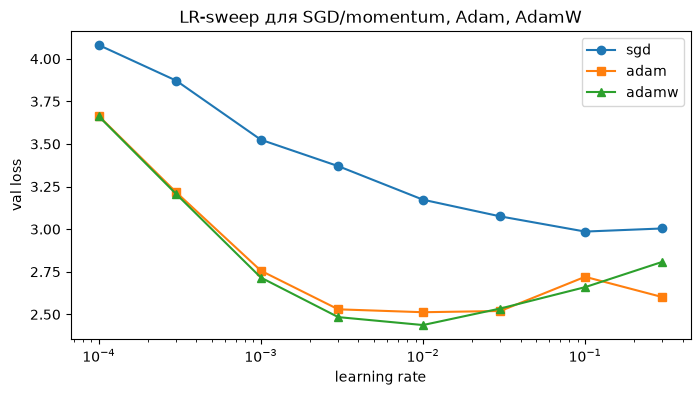

In [7]:
def train_run(cfg, opt_name, lr, steps, schedule="cosine", warmup_frac=0.1, wd=0.1, B=32, seed=SEED, log_diag=False, param_groups=None, model=None):
    set_seed(seed); model = model or GPT(cfg).to(DEVICE)
    params = param_groups(model, lr) if param_groups else [{"params": model.parameters(), "lr": lr}]
    if opt_name == "sgd": opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=0.0)
    elif opt_name == "adam": opt = torch.optim.Adam(params, lr=lr, betas=(0.9, 0.95), weight_decay=wd * 1e-2)
    else: opt = torch.optim.AdamW(params, lr=lr, betas=(0.9, 0.95), weight_decay=wd)
    warm = int(warmup_frac * steps)

    # (множитель LR как функция шага для "constant", "cosine" и "wsd" (последние 20% — линейный спад))
    def lr_mult(s):
        w = min(1.0, (s + 1) / max(warm, 1)) 
        
        if schedule == "constant":
            return w
        if schedule == "cosine":
            return w * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps))
        if schedule == "wsd":
            decay_start = int(0.8 * steps)
            if s < decay_start:
                return w
            prog = (s - decay_start) / max(steps - decay_start, 1)
            return w * max(0.0, 1.0 - prog)
        return w

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_mult)
    hist, diag = [], []
    for s in range(steps):
        x, y = get_batch(train_data, cfg.block_size, B)
        loss = model(x, y)[1]
        if not torch.isfinite(loss): hist.append((s, float("nan"))); break
        opt.zero_grad(set_to_none=True); loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1e9 if log_diag else 1.0)
        if log_diag: diag.append(diagnostics(model, opt, x, gn.item(), loss.item()))
        opt.step(); sched.step(); hist.append((s, loss.item()))
    val = estimate_loss(model, val_data, cfg.block_size, iters=10) if math.isfinite(hist[-1][1]) else float("nan")
    return model, hist, val, diag

LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
sweep = {}
for opt_name in ("sgd", "adam", "adamw"):
    for lr in LRS:
        _, _, val, _ = train_run(SMALL, opt_name, lr, SWEEP_STEPS)
        sweep[(opt_name, lr)] = val
        print(f"{opt_name:5s}  lr={lr:<8g}  val={val}")

fig, ax = plt.subplots(figsize=(8, 4))
markers = {"sgd": "o", "adam": "s", "adamw": "^"}
for opt_name in ("sgd", "adam", "adamw"):
    lrs_ok = [lr for lr in LRS if math.isfinite(sweep[(opt_name, lr)])]
    vals_ok = [sweep[(opt_name, lr)] for lr in lrs_ok]
    ax.plot(lrs_ok, vals_ok, marker=markers[opt_name], label=opt_name)
ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("val loss")
ax.legend(); ax.set_title("LR-sweep для SGD/momentum, Adam, AdamW"); plt.show()

## 3. Расписания

Для AdamW с лучшим LR сравните три расписания на одинаковом числе шагов: constant (с warmup), warmup + cosine, WSD (warmup–stable–decay с линейным спадом на последних 20% шагов). Постройте кривые train loss (скользящее среднее) и объясните характерную ступеньку WSD в фазе спада.

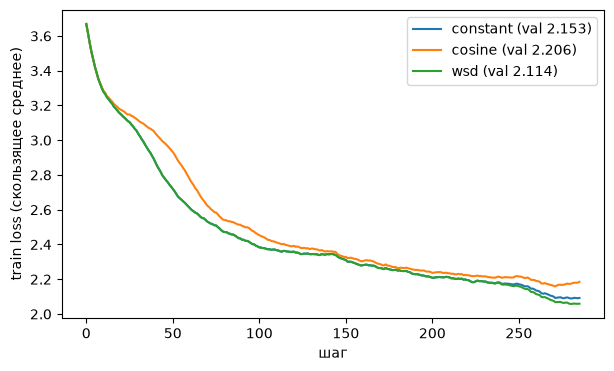

In [8]:
best_lr = min((v, lr) for (o, lr), v in sweep.items() if o == "adamw" and math.isfinite(v))[1]
plt.figure(figsize=(7, 4))
for sch in ("constant", "cosine", "wsd"):
    _, h, val, _ = train_run(SMALL, "adamw", best_lr, 2 * SWEEP_STEPS, schedule=sch)
    l = np.array([v for _, v in h]); sm = np.convolve(l, np.ones(15) / 15, mode="valid")
    plt.plot(sm, label=f"{sch} (val {val:.3f})")
plt.xlabel("шаг"); plt.ylabel("train loss (скользящее среднее)"); plt.legend(); plt.show()

## 4. Всплески loss и их диагностика

Запустите AdamW с LR в 3–10 раз больше оптимального **без warmup** и без gradient clipping. На каждом шаге логируйте:

- норму градиента;
- максимальный логит attention $\max_{i,j} q_i^\top k_j / \sqrt{d}$ по всем слоям;
- среднее отношение $\|\Delta\theta\| / \|\theta\|$ за шаг (оценка через $\eta\,\|\hat m / (\sqrt{\hat v} + \varepsilon)\|$);
- долю координат с очень малым $\hat v$ ($\sqrt{\hat v} < 10^{-8}$).

Найдите шаги со всплесками loss и посмотрите, какие показатели меняются перед ними.


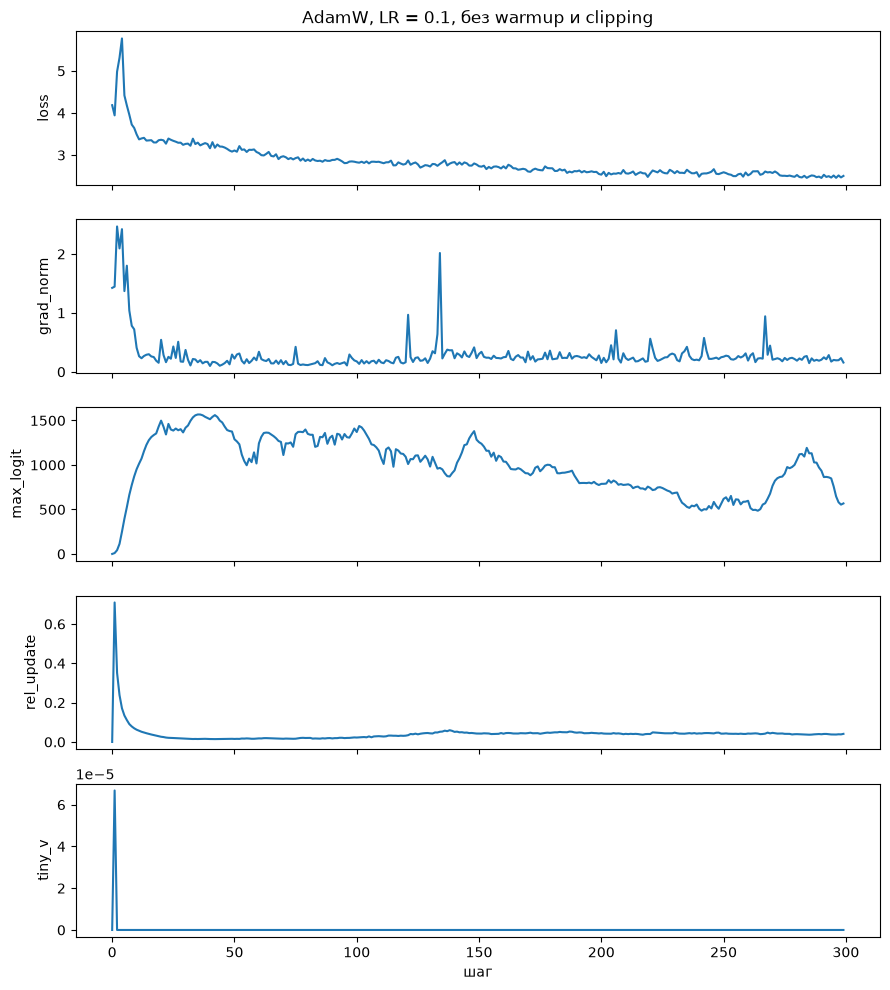

In [20]:
captured = {}
def _hook(name):
    def f(mod, inp, out): captured[name] = inp[0].detach()
    return f
def attach_hooks(model):
    for i, b in enumerate(model.blocks): b.attn.register_forward_hook(_hook(i))

@torch.no_grad()
def max_attn_logit(model):
    #  (из captured[i] (вход attention) пересчитайте q, k с RoPE и найдите максимум каузальных логитов)
    mx = -float("inf")
    for i, b in enumerate(model.blocks):
        x = captured[i]
        B, T, C = x.shape
        attn = b.attn

        q, k, _ = attn.qkv(x).split(C, dim=2)
        d_head = attn.d_head; nh = attn.n_head

        q = q.view(B, T, nh, d_head).transpose(1, 2)
        k = k.view(B, T, nh, d_head).transpose(1, 2)

        q = apply_rope(q, model.cos[:T], model.sin[:T])
        k = apply_rope(k, model.cos[:T], model.sin[:T])
        
        logits = (q @ k.transpose(-2, -1)) / math.sqrt(d_head)
        mask = torch.triu(torch.ones(T, T, device=logits.device, dtype=torch.bool), diagonal=1)
        
        logits = logits.masked_fill(mask, -float("inf"))
        mx = max(mx, logits.max().item())
    return mx

@torch.no_grad()
def diagnostics(model, opt, x, grad_norm, loss):
    rel_upd, tiny_v, n = 0.0, 0, 0
    for g in opt.param_groups:
        for p in g["params"]:
            st = opt.state.get(p, {})
            if "exp_avg" in st and st.get("step", 0):
                t = float(st["step"]); b1, b2 = g["betas"]
                m_hat = st["exp_avg"] / (1 - b1 ** t); v_hat = st["exp_avg_sq"] / (1 - b2 ** t)
                upd = g["lr"] * m_hat / (v_hat.sqrt() + g["eps"])
                rel_upd += (upd.norm() / (p.norm() + 1e-12)).item(); n += 1
                tiny_v += (v_hat.sqrt() < 1e-8).float().mean().item()
    return {"loss": loss, "grad_norm": grad_norm, "max_logit": max_attn_logit(model),
            "rel_update": rel_upd / max(n, 1), "tiny_v": tiny_v / max(n, 1)}

set_seed(); spike_model = GPT(SMALL).to(DEVICE); attach_hooks(spike_model)
_, h, val, diag = train_run(SMALL, "adamw", 10 * best_lr, 2 * SWEEP_STEPS, schedule="constant", warmup_frac=0.0,
                            log_diag=True, model=spike_model)
keys = ["loss", "grad_norm", "max_logit", "rel_update", "tiny_v"]
fig, axes = plt.subplots(len(keys), 1, figsize=(9, 10), sharex=True)
for ax, k in zip(axes, keys):
    ax.plot([d[k] for d in diag]); ax.set_ylabel(k)
axes[0].set_title(f"AdamW, LR = {10 * best_lr:g}, без warmup и clipping"); axes[-1].set_xlabel("шаг"); plt.tight_layout(); plt.show()

In [16]:
# (найдите шаги, где loss вырос более чем на 20% относительно скользящего минимума, и выведите показатели за 5 шагов до всплеска)
losses = np.array([d["loss"] for d in diag])

prev_min = losses[0]; spikes = []
for i in range(1, len(losses)):
    if losses[i] > 1.2 * prev_min:
        spikes.append(i)
    prev_min = min(prev_min, losses[i])
print(f"шагов: {len(losses)}, всплесков: {len(spikes)}, первые: {spikes[:5]}")

for s in spikes[:3]:
    print(f"\nвсплеск на шаге {s} (loss={losses[s]:.4f})")
    for j in range(max(0, s - 5), s):
        d = diag[j]
        print(f"  step {j}: loss={d['loss']:.4f} "
                f"gn={d['grad_norm']:.3f} max_logit={d['max_logit']:.2f} "
                f"rel_upd={d['rel_update']:.2e} tiny_v={d['tiny_v']:.4f}")


шагов: 300, всплесков: 3, первые: [2, 3, 4]

всплеск на шаге 2 (loss=4.9824)
  step 0: loss=4.1855 gn=1.424 max_logit=0.13 rel_upd=0.00e+00 tiny_v=0.0000
  step 1: loss=3.9440 gn=1.446 max_logit=10.08 rel_upd=7.09e-01 tiny_v=0.0001

всплеск на шаге 3 (loss=5.3129)
  step 0: loss=4.1855 gn=1.424 max_logit=0.13 rel_upd=0.00e+00 tiny_v=0.0000
  step 1: loss=3.9440 gn=1.446 max_logit=10.08 rel_upd=7.09e-01 tiny_v=0.0001
  step 2: loss=4.9824 gn=2.467 max_logit=42.20 rel_upd=3.51e-01 tiny_v=0.0000

всплеск на шаге 4 (loss=5.7714)
  step 0: loss=4.1855 gn=1.424 max_logit=0.13 rel_upd=0.00e+00 tiny_v=0.0000
  step 1: loss=3.9440 gn=1.446 max_logit=10.08 rel_upd=7.09e-01 tiny_v=0.0001
  step 2: loss=4.9824 gn=2.467 max_logit=42.20 rel_upd=3.51e-01 tiny_v=0.0000
  step 3: loss=5.3129 gn=2.094 max_logit=113.16 rel_upd=2.38e-01 tiny_v=0.0000


## 5. Упрощённый $\mu$P по ширине

Сравните стандартную параметризацию (SP) и $\mu$P при ширинах $d \in \{64, 128, 256\}$ (в полном режиме до 512) с фиксированной глубиной. Правила $\mu$P для Adam (Yang et al., 2022, упрощённо):

- скрытые матрицы (attention, FFN): инициализация $\mathcal{N}(0, 1/d)$, learning rate $\eta \cdot d_0/d$;
- эмбеддинги: обычный learning rate $\eta$;
- выходной слой: не связан с эмбеддингами, инициализирован нулём, логиты умножаются на $d_0/d$;
- attention: масштаб $1/d_{head}$ вместо $1/\sqrt{d_{head}}$ (в упрощённой версии можно оставить $1/\sqrt{d_{head}}$ при фиксированном $d_{head}$).

Здесь $d_0 = 64$ — базовая ширина. Для каждой параметризации и ширины найдите оптимальный LR и проверьте, сохраняется ли он при росте ширины.


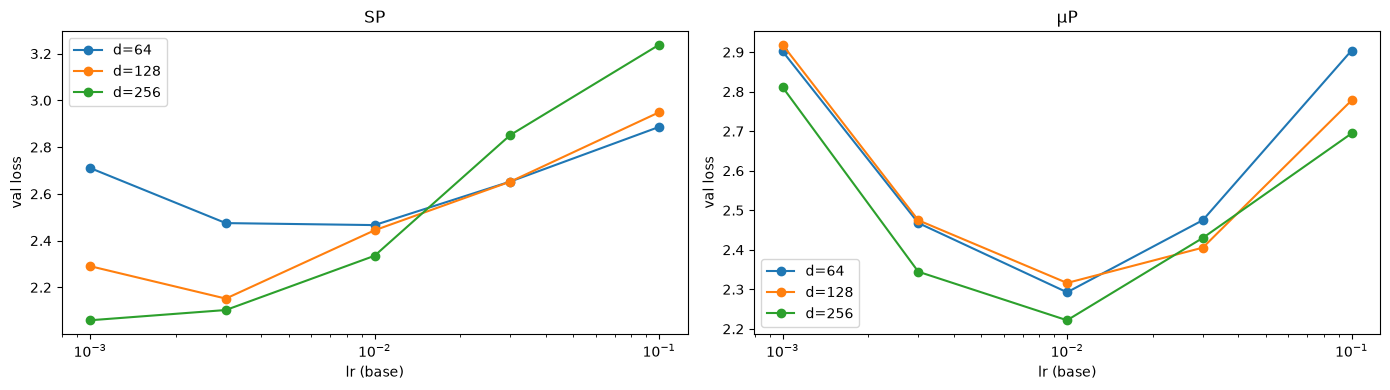

In [ ]:
def make_mup(cfg, base_d=64):
    # ваш код (отвяжите head от wte, обнулите его, добавьте forward hook, умножающий логиты на mult; инициализация скрытых матриц N(0, 1/d))
    model = GPT(cfg).to(DEVICE)
    d = cfg.n_embd; 
    mult = base_d / d

    model.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False).to(DEVICE)
    nn.init.zeros_(model.head.weight)
    model.head.register_forward_hook(lambda m, inp, out: out * mult)

    with torch.no_grad():
        for n, p in model.named_parameters():
            if p.dim() == 2 and not n.startswith(("wte", "head")):
                nn.init.normal_(p, 0.0, 1.0 / math.sqrt(d))
    return model

def mup_groups(base_d=64):
    def f(model, lr):
        d = model.cfg.n_embd
        hidden = [p for n, p in model.named_parameters() if p.dim() == 2 and not n.startswith(("wte", "head"))]
        other = [p for n, p in model.named_parameters() if not (p.dim() == 2 and not n.startswith(("wte", "head")))]
        return [{"params": hidden, "lr": lr * base_d / d}, {"params": other, "lr": lr}]
    return f

WIDTHS = [64, 128, 256] if FAST_DEV_RUN else [64, 128, 256, 512]
MUP_LRS = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]

# (sweep SP и μP по ширинам и LR, два графика val loss(LR) с кривой на каждую ширину)
sp_res, mup_res = {}, {}
for d in WIDTHS:
    cfg = GPTConfig(tok.vocab_size, 64, 2, 4, d)
    for lr in MUP_LRS:
        # SP
        _, _, v, _ = train_run(cfg, "adamw", lr, SWEEP_STEPS, wd=0.0)
        sp_res[(d, lr)] = v
        # μP
        m = make_mup(cfg)
        _, _, v, _ = train_run(cfg, "adamw", lr, SWEEP_STEPS, wd=0.0,
                               param_groups=mup_groups(64), model=m)
        mup_res[(d, lr)] = v

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, res, title in [(axes[0], sp_res, "SP"), (axes[1], mup_res, "μP")]:
    for d in WIDTHS:
        lrs_ok = [lr for (dd, lr) in res if dd == d and math.isfinite(res[(dd, lr)])]
        vals_ok = [res[(d, lr)] for lr in lrs_ok]
        ax.plot(lrs_ok, vals_ok, marker="o", label=f"d={d}")
    ax.set_xscale("log"); ax.set_xlabel("lr (base)"); ax.set_ylabel("val loss")
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## Вопросы

1. Вычислите величину первого шага Adam без bias correction при \(\beta_1 = 0.9\), \(\beta_2 = 0.999\) и сравните с шагом при bias correction. Объясните, почему warmup частично решает ту же проблему.
2. Почему L2-регуляризация в Adam не эквивалентна weight decay, а в SGD эквивалентна?
3. Какие показатели в п. 4 предшествуют всплескам? Предложите меры: какие из них устраняют причину, а какие — симптомы (QK-norm, z-loss, clipping, уменьшение \(\beta_2\), \(\varepsilon\))?
4. Почему WSD удобнее cosine для экспериментов со scaling laws и для дообучения?
5. Какое свойство μP позволяет переносить гиперпараметры с маленькой модели на большую? Что произошло с оптимальным LR в SP при росте ширины в вашем эксперименте?

Вывод: реализовали свой AdamW. Подобрали learning rate для SGD с momentum, Adam и AdamW и посмотрели, где обучение стабильно, а где ломается. Сравнили три расписания: постоянное, warmup+cosine и WSD, и увидели, как меняется loss. Отдельно запустили AdamW с слишком большим LR и без защиты, чтобы найти всплески loss и понять, какие показатели растут перед ними. В конце проверили упрощённый μP на разных ширинах модели и посмотрели, сохраняется ли оптимальный learning rate при увеличении ширины.